<a href="https://colab.research.google.com/github/Md-Ifat-Hassan/pipeline-leak-detection/blob/main/pipeline_leak_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

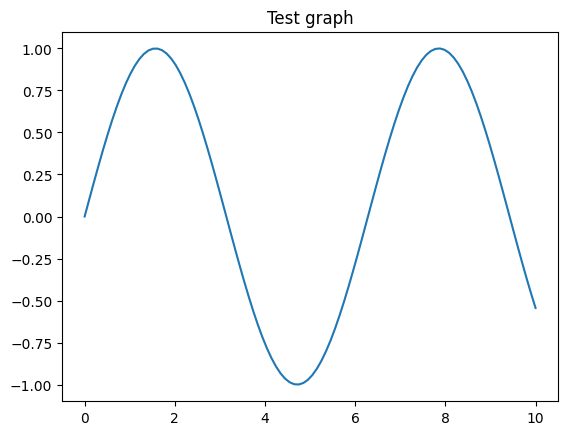

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(0, 10, 100)
plt.plot(x, np.sin(x))
plt.title("Test graph")
plt.show()

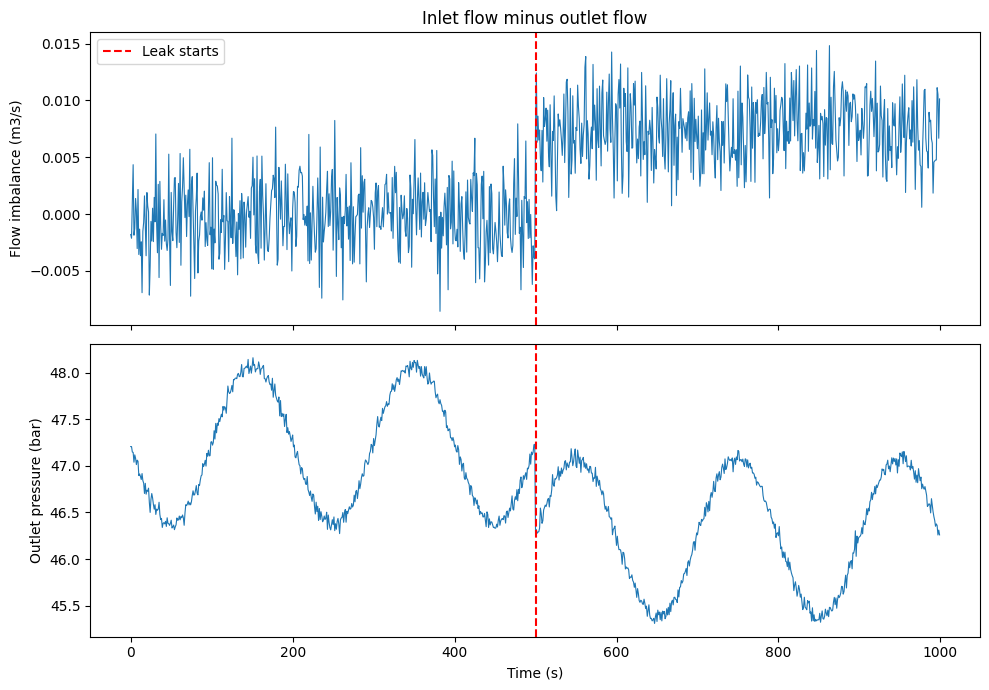

In [2]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

# ---- Pipe parameters (approximate, cite sources later) ----
L = 10000        # length, m
D = 0.3          # diameter, m
rho = 850        # oil density, kg/m3
f = 0.02         # friction factor
P_in = 60e5      # inlet pressure, Pa
A = np.pi * (D / 2) ** 2

T = 1000
t = np.arange(T)


def simulate_pipeline(t, q_nominal=0.15, flow_var=0.005):
    q_in = q_nominal + flow_var * np.sin(2 * np.pi * t / 200)
    v = q_in / A
    dp = f * (L / D) * (rho * v**2 / 2)
    p_in = np.full(len(t), P_in)
    p_out = p_in - dp
    return q_in, p_in, p_out


def add_noise(x, sigma):
    return x + np.random.normal(0, sigma, size=x.shape)


def inject_leak(q_in, p_out, start, size):
    q_out = q_in.copy()
    p_out = p_out.copy()
    q_out[start:] = q_in[start:] * (1 - size)
    p_out[start:] -= size * 20e5
    return q_out, p_out


q_in, p_in, p_out = simulate_pipeline(t)

LEAK_START = 500
LEAK_SIZE = 0.05
q_out, p_out_leak = inject_leak(q_in, p_out, LEAK_START, LEAK_SIZE)

q_in_m = add_noise(q_in, 0.002)
q_out_m = add_noise(q_out, 0.002)
p_out_m = add_noise(p_out_leak, 0.05e5)

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

axes[0].plot(t, q_in_m - q_out_m, linewidth=0.8)
axes[0].axvline(LEAK_START, color="red", linestyle="--", label="Leak starts")
axes[0].set_ylabel("Flow imbalance (m3/s)")
axes[0].set_title("Inlet flow minus outlet flow")
axes[0].legend()

axes[1].plot(t, p_out_m / 1e5, linewidth=0.8)
axes[1].axvline(LEAK_START, color="red", linestyle="--")
axes[1].set_ylabel("Outlet pressure (bar)")
axes[1].set_xlabel("Time (s)")

plt.tight_layout()
plt.show()